# Completely formal economy: equilibrium and welfare, with and without monotributo

**Question.** Suppose *every* worker in Argentina is formal. Workers are either high-income (FH) or low-income (FL), and they move between the two at the rates estimated from the EPH panel. We compare two tax regimes:

| Economy | Tax rule | $\tau_{FH}$ | $\tau_{FL}$ |
|---|---|---|---|
| **A: with monotributo** | high earners pay the full regime, low earners the simplified regime | 0.19 | 0.05 |
| **B: without monotributo** | everyone pays the same rate: the weighted average $\bar\tau=p_{FH}\cdot0.19+p_{FL}\cdot0.05\approx0.158$ | $\bar\tau$ | $\bar\tau$ |

Tax revenue is **thrown away** in both economies (no transfers, no public spending). Agents cannot choose their sector: the income state is an exogenous Markov process (the human-capital shock).

**What this notebook computes, one step at a time**
1. The equilibrium interest rate $r^*$ in A and in B.
2. The expected welfare of an agent who starts with assets $a_0$ and income state $j_0$, in A and in B.
3. The expected aggregate welfare in A and in B.

The solver follows the Galindo et al. 2-state Huggett model of notebook `4. equilibrium_2state_arg.ipynb` (finite differences, upwind scheme, implicit Euler, Fokker-Planck). The only structural change is that the two states are now **FH and FL** instead of I and F.

---
## Assumption log

Every choice that is not taken directly from the thesis is listed here. **DECIDE** = needs your confirmation; the sensitivity section at the end shows how much each DECIDE item matters.

| ID | Assumption | Source | Status |
|---|---|---|---|
| A1 | Two states only: FH and FL. No informal state, no sector choice. | your request | fixed |
| A2 | Incomes: $z_{FH}=1$, $z_{FL}=0.3211$ (FL/FH, EPH). | thesis calibration (notebook 5) | fixed |
| A3 | **Transition intensities = Option 2.** Annual generator from the quarterly EPH matrix $P$: $\Lambda^{4}=\log(P)/0.25$ (negative off-diagonals set to 0, as in `2. galindo_lambdas_4state.R`), **without** the rescaling to the 42% informality target. Then keep the FH/FL block and drop the exits to informality (diagonal recomputed). Option 1 (calibrated 4-state $\Lambda$) and Option 3 (quarterly $P$ conditioned on staying formal) are in Step 1 and in the sensitivity table. | `data/output_data/transition_matrix_4state.csv` | chosen by you (Option 2) |
| A4 | Risk aversion is the same in both states: $\gamma=0.15$ (the thesis *formal* value). | your request | fixed |
| A5 | Discount rate $\rho=0.03$. | fixed in your earlier instructions | fixed |
| A6 | No borrowing premium ($\theta=0$): borrowers and savers face the same $r$. | no informal sector, so no premium | fixed |
| A7 | Borrowing limit $a_{\min}=-0.099$ (about 1.8 months of mean income). | thesis value | **DECIDE** |
| A8 | "Without monotributo" means one tax rate for everyone, equal to the weighted average of A's rates, $\bar\tau=p_{FH}\cdot0.19+p_{FL}\cdot0.05$, with $p$ the ergodic shares of Step 1 (about 0.158). In the sensitivity rows that change $\Lambda$, $\bar\tau$ is recomputed with that $\Lambda$'s shares. | your instruction | fixed (19% and 17% for all are in the sensitivity section) |
| A9 | Tax revenue is thrown away. Asset market clearing is $\int a\,g = 0$ (net private assets are zero; there is no government debt). | your request | fixed |
| A10 | Time unit is one year ($\Lambda$ is annual). | thesis | fixed |
| A11 | Welfare of an agent = expected discounted utility $V(a_0,j_0)$ under the optimal policy. Aggregate welfare = $V$ averaged over the economy's own stationary distribution $g$. | your request | fixed |
| A12 | Welfare differences are also reported as a consumption-equivalent variation (CEV). This is an extra, only for interpretation. | added by me | **DECIDE** |
| A13 | **HJB solver = notebook 3's solver.** Same upwind lines (`If = ssf>0`, `Ib = ssb<0`, `I0 = 1-If-Ib`, generator from both drifts), no consumption cap, and every bisection step starts from the previous $V$ (warm start), as in notebook 3's `find_equilibrium`. Only difference: HJB tolerance $10^{-8}$ instead of $10^{-6}$ (tighter). | as in notebooks 3/4/5/8 | numerical only |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import spdiags, eye, bmat
from scipy.sparse.linalg import spsolve
from scipy.linalg import logm
from IPython.display import display

plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "axes.grid": True,
                     "grid.color": "#e8e8e8", "legend.frameon": False, "figure.dpi": 110})
pd.set_option("display.width", 140)
DATA = "../data"          # repo data folder (this notebook lives in building_pipeline/)
C_A, C_B = "#1f4e9c", "#d9730d"   # colour for economy A (monotributo) and B (no monotributo)

---
# Step 1. Import the transition matrix of a completely formal economy

**Where the numbers come from.** `0. clean_data.R` builds, from the EPH panel, the quarterly transition matrix $P$ over the four states (FH, FL, IH, IL), saved in `data/output_data/transition_matrix_4state.csv`. Entry $P_{jk}$ is the probability of being in state $k$ next quarter given state $j$ today.

**Option 2 (A3, used here), in two steps.**

*Step 1a: quarterly probabilities $\to$ annual intensities.* A continuous-time Markov chain with generator $\Lambda$ has quarterly transition matrix $P=e^{0.25\,\Lambda}$. Inverting,
$$\Lambda^{4}=\frac{\log P}{0.25}\qquad(\text{matrix logarithm}).$$
Entry $\lambda_{jk}$ ($j\neq k$) is the annual rate of moving from $j$ to $k$. If any off-diagonal entry comes out negative it is set to 0, and the diagonal is recomputed so that rows sum to zero. This is the same first step as in `2. galindo_lambdas_4state.R`, but we stop here: we do **not** apply that script's rescaling of the rates to hit 42% informality.

*Step 1b: switch off informality.* Keep the 2x2 FH/FL block of $\Lambda^4$ and drop every move into informality. The within-formal rates $\lambda_{FH\to FL}$ and $\lambda_{FL\to FH}$ stay as estimated, and the diagonal is recomputed:
$$\lambda_{jj} = -\sum_{k\ne j}\lambda_{jk}.$$
Interpretation: a formal worker who would have become informal in the data instead stays in their current formal state.

In [2]:
P4 = pd.read_csv(f"{DATA}/output_data/transition_matrix_4state.csv", index_col=0)
STATES4 = ["FH", "FL", "IH", "IL"]
P4 = P4.loc[STATES4, STATES4]
print("Quarterly transition matrix P from the EPH (rows = from, columns = to):")
display(P4.round(4))
print("Row sums:", P4.values.sum(axis=1).round(10))

Quarterly transition matrix P from the EPH (rows = from, columns = to):


,FH,FL,IH,IL
state_t,,,,
FH,0.8539,0.0880,0.0322,0.0260
FL,0.2910,0.5522,0.0265,0.1303
IH,0.1744,0.0702,0.4356,0.3198
IL,0.0395,0.0669,0.0796,0.8140


Row sums: [1. 1. 1. 1.]


In [3]:
def generator_from_P(P, dt=0.25):
    # Step 1a: annual generator from a transition matrix over dt years; negative off-diagonals -> 0, rows sum to 0
    L = np.real(logm(np.asarray(P, float))) / dt
    off = ~np.eye(L.shape[0], dtype=bool)
    n_neg = int((L[off] < 0).sum())
    L[off & (L < 0)] = 0.0
    np.fill_diagonal(L, 0.0); np.fill_diagonal(L, -L.sum(axis=1))
    return L, n_neg

L4_mat, n_neg = generator_from_P(P4.values)
L4 = pd.DataFrame(L4_mat, index=STATES4, columns=STATES4)
print(f"Step 1a. Annual 4-state generator log(P)/0.25  (negative off-diagonals set to 0: {n_neg})")
display(L4.round(4))

Step 1a. Annual 4-state generator log(P)/0.25  (negative off-diagonals set to 0: 0)


,FH,FL,IH,IL
FH,-0.7476,0.5076,0.1987,0.0413
FL,1.6951,-2.5490,0.1098,0.7441
IH,1.0308,0.3850,-3.5433,2.1275
IL,0.0651,0.3738,0.5327,-0.9717


In [4]:
FORMAL = ["FH", "FL"]
def drop_informality(L4df):
    # Step 1b: keep the FH/FL block, rebuild the diagonal
    L = L4df.loc[FORMAL, FORMAL].values.astype(float).copy()
    np.fill_diagonal(L, 0.0); np.fill_diagonal(L, -L.sum(axis=1))
    return L

print("Raw FH/FL block (diagonal still includes the exits to informality):")
display(L4.loc[FORMAL, FORMAL].round(4))
Lam_F = drop_informality(L4)
print("Formal-only generator, Option 2 (A3):")
display(pd.DataFrame(Lam_F, index=FORMAL, columns=FORMAL).round(4))
print("Row sums:", Lam_F.sum(axis=1))

lam_HL, lam_LH = Lam_F[0, 1], Lam_F[1, 0]
print(f"\nlambda_FH->FL = {lam_HL:.4f} per year  (expected stay in FH: {1/lam_HL:.2f} years)")
print(f"lambda_FL->FH = {lam_LH:.4f} per year  (expected stay in FL: {1/lam_LH:.2f} years)")

Raw FH/FL block (diagonal still includes the exits to informality):


,FH,FL
FH,-0.7476,0.5076
FL,1.6951,-2.5490


Formal-only generator, Option 2 (A3):


,FH,FL
FH,-0.5076,0.5076
FL,1.6951,-1.6951


Row sums: [0. 0.]

lambda_FH->FL = 0.5076 per year  (expected stay in FH: 1.97 years)
lambda_FL->FH = 1.6951 per year  (expected stay in FL: 0.59 years)


**Check 1: ergodic shares.** In a 2-state chain the long-run share in FH is $p_{FH}=\lambda_{LH}/(\lambda_{HL}+\lambda_{LH})$. The Fokker-Planck solution later must reproduce this number, because the income process does not depend on assets.

In [5]:
def stationary(L):
    # left null vector of the generator: p L = 0, sum p = 1
    w, v = np.linalg.eig(np.asarray(L).T)
    p = np.real(v[:, np.argmin(np.abs(w))])
    return p / p.sum()

p_F = stationary(Lam_F)
print(f"Formal-only economy: share FH = {p_F[0]:.4f}, share FL = {p_F[1]:.4f}")
print(f"Closed form lam_LH/(lam_HL+lam_LH) = {lam_LH/(lam_HL+lam_LH):.4f}")
p_4 = stationary(L4.values)
print(f"\nFor reference, the 4-state data generator has (FH,FL,IH,IL) = {np.round(p_4,3)}")
print(f"  -> formal workers are {p_4[:2].sum():.1%} of the population there; "
      f"within formal, FH is {p_4[0]/p_4[:2].sum():.1%}")

Formal-only economy: share FH = 0.7696, share FL = 0.2304
Closed form lam_LH/(lam_HL+lam_LH) = 0.7696

For reference, the 4-state data generator has (FH,FL,IH,IL) = [0.471 0.15  0.077 0.302]
  -> formal workers are 62.1% of the population there; within formal, FH is 75.9%


### 1c. The two other options (sensitivity only)
- **Option 1: calibrated 4-state matrix, informality switched off.** Start from `data/lambda_matrix_4state_datadriven.csv`, which is $\log(P)/0.25$ **after** `2. galindo_lambdas_4state.R` rescaled groups of rates so the 4-state model hits 42% informality. Then apply step 1b. The only difference from Option 2 is that rescaling.
- **Option 3: condition on staying formal.** Take the FH/FL block of the quarterly $P$, divide each row by its sum ($\tilde P_{jk}=P_{jk}/(P_{j,FH}+P_{j,FL})$), then apply $\log(\tilde P)/0.25$. Informality is removed in the quarterly probabilities rather than in the annual rates. Moves that pass through informality within a quarter count as formal-to-formal moves, and only workers who stay formal are kept.

**Data-file check.** Option 1's saved matrix should reproduce the quarterly $P$ only up to its rescaling. The cell below also reports how far $e^{0.25\Lambda}$ of the saved matrix is from the $P$ file. A large gap means the saved matrix was estimated from a different version of $P$ than the one in the repo.

In [6]:
L4_opt1 = pd.read_csv(f"{DATA}/lambda_matrix_4state_datadriven.csv", index_col=0).loc[STATES4, STATES4]
Lam_F_opt1 = drop_informality(L4_opt1)

Pff = P4.loc[FORMAL, FORMAL].values.astype(float)
Pff = Pff / Pff.sum(axis=1, keepdims=True)           # condition on staying formal
Lam_F_opt3, _ = generator_from_P(Pff)

opts = {"Option 2 (A3, baseline)": Lam_F, "Option 1 (calibrated 4-state)": Lam_F_opt1, "Option 3 (conditioned P)": Lam_F_opt3}
cmp = pd.DataFrame({k: {"lambda FH->FL": L[0, 1], "lambda FL->FH": L[1, 0], "FH spell (years)": 1 / L[0, 1],
                        "FL spell (years)": 1 / L[1, 0], "share FH": stationary(L)[0]} for k, L in opts.items()}).T
display(cmp.round(4))

from scipy.linalg import expm
gap = np.abs(expm(0.25 * L4_opt1.values) - P4.values).max()
print(f"Data-file check: max |exp(0.25 * Lambda_opt1) - P| = {gap:.3f}  (Option 2: {np.abs(expm(0.25 * L4.values) - P4.values).max():.1e})")

,lambda FH->FL,lambda FL->FH,FH spell (years),FL spell (years),share FH
"Option 2 (A3, baseline)",0.5076,1.6951,1.9701,0.5899,0.7696
Option 1 (calibrated 4-state),0.6781,1.7998,1.4747,0.5556,0.7263
Option 3 (conditioned P),0.4918,1.8168,2.0332,0.5504,0.7870


Data-file check: max |exp(0.25 * Lambda_opt1) - P| = 0.066  (Option 2: 8.9e-16)


---
# Step 2. Parameters

All parameters live in one dictionary so that nothing drifts between functions (same idea as `make_params` in notebook 4). The model has $N=2$ states ordered **[FH, FL]**.

In [7]:
def make_params(Lam, rho=0.03, z=(1.0, 0.321119145), gamma=(0.15, 0.15),
                I=800, amin=-0.099, amax=5.0, Delta=1000.0, maxit=400):
    a = np.linspace(amin, amax, I)
    return dict(Lam=np.array(Lam, float), rho=rho, z=np.array(z, float), gamma=np.array(gamma, float),
                I=I, N=len(z), a=a, da=a[1] - a[0], amin=amin, amax=amax, Delta=Delta, maxit=maxit)

params = make_params(Lam_F)

# The two economies differ ONLY in the tax vector [tau_FH, tau_FL]  (A8)
ECON_A = dict(name="A: with monotributo",    tau=np.array([0.19, 0.05]))
TAU_BAR = p_F[0] * 0.19 + p_F[1] * 0.05      # A8: weighted average of A's rates
ECON_B = dict(name="B: without monotributo", tau=np.array([TAU_BAR, TAU_BAR]))
print(f"Weighted-average tax in B: {TAU_BAR:.4f}")

tab = pd.DataFrame({"z (pre-tax income)": params["z"], "gamma": params["gamma"],
                    "tau in A": ECON_A["tau"], "tau in B": ECON_B["tau"],
                    "after-tax income in A": (1-ECON_A["tau"])*params["z"],
                    "after-tax income in B": (1-ECON_B["tau"])*params["z"]}, index=FORMAL)
display(tab.round(4))
print(f"rho = {params['rho']}, grid: I={params['I']} points on [{params['amin']}, {params['amax']}], da={params['da']:.5f}")

Weighted-average tax in B: 0.1577


,z (pre-tax income),gamma,tau in A,tau in B,after-tax income in A,after-tax income in B
FH,1.0000,0.15,0.19,0.1577,0.8100,0.8423
FL,0.3211,0.15,0.05,0.1577,0.3051,0.2705


rho = 0.03, grid: I=800 points on [-0.099, 5.0], da=0.00638


---
# Step 3. The model

**Agent problem.** An agent in income state $j\in\{FH,FL\}$ with assets $a$ chooses consumption $c$ to maximise discounted CRRA utility. Assets earn $r$ (the same for savers and borrowers, A6), after-tax labour income is $(1-\tau_j)z_j$, and $a\ge a_{\min}$:

$$\dot a = (1-\tau_j)z_j + r a - c, \qquad u(c)=\frac{c^{1-\gamma}}{1-\gamma}\quad(\gamma=0.15 \text{ in both states, A4}).$$

**HJB equation.** The income state jumps from $j$ to $k$ at rate $\lambda_{jk}$:

$$\rho V_j(a)=\max_c\Big\{u(c)+V_j'(a)\,\big[(1-\tau_j)z_j+ra-c\big]\Big\}+\sum_{k\neq j}\lambda_{jk}\big[V_k(a)-V_j(a)\big].$$

Because $\gamma=0.15<1$, $u(c)>0$ for every $c>0$, hence $V>0$ everywhere. This matters for the CEV in Step 6.

**First-order condition.** $u'(c)=V_j'(a)$, so $c_j(a)=\big(V_j'(a)\big)^{-1/\gamma}$.

**Numerical scheme (same as notebook 4).**
- Upwind finite differences: use the forward derivative where savings are positive, the backward derivative where savings are negative. This block is copied from notebook 3 (A13).
- State constraint at $a_{\min}$: the backward derivative there is $u'\big((1-\tau_j)z_j+ra_{\min}\big)$, i.e. the agent cannot dissave.
- Warm start: when solving at a new $r$, start from the $V$ of the previous $r$ (notebook 3 does the same in its bisection). From a cold guess the iteration can break down at some $r$ (consumption explodes at a grid point and the generator check fails), so warm starts are needed, not just faster.
- Implicit Euler on a pseudo-time step $\Delta=1000$: $\big(\tfrac1\Delta+\rho\big)V^{n+1}-\mathcal A V^{n+1}=u(c^n)+\tfrac1\Delta V^n$, where $\mathcal A$ is the generator (asset drift + income switching). Iterate until $\max|V^{n+1}-V^n|<10^{-8}$.

**Stationary distribution.** The density $g_j(a)$ solves $\mathcal A^\top g=0$ with $\sum_j\int g_j\,da=1$ (Fokker-Planck). One equation of the singular system is replaced by the normalisation.

**Equilibrium.** Net private assets are zero: $S(r)=\sum_j\int a\,g_j(a;r)\,da=0$. With tax revenue thrown away, there is no government in the market-clearing condition (A9).

### 3a. The functions
`policy_step` is **one** HJB iteration (derivatives, consumption, drift, generator). It is separated from the loop so that Step 4 can open it up and print each object. `solve_given_r` loops it to convergence and then computes the stationary distribution.

In [8]:
def u(c, gam):  return np.maximum(c, 1e-12) ** (1 - gam) / (1 - gam)
def up(c, gam): return np.maximum(c, 1e-12) ** (-gam)

def build_Aswitch(I, Lam):
    # income-state switching: block (j,k) = lambda_jk * Identity on the asset grid
    N = Lam.shape[0]
    return bmat([[Lam[i, j] * eye(I) for j in range(N)] for i in range(N)], format="csc")

def initial_V(r, tau, p):
    # guess: consume current after-tax income forever, V = u(z_after_tax + r a) / rho
    zat = (1 - tau) * p["z"]
    c0 = np.maximum(zat[None, :] + r * p["a"][:, None], 1e-12)
    return u(c0, p["gamma"][None, :]) / p["rho"]

def policy_step(V, r, tau, p):
    # One HJB iteration, split into the pieces of Step 4.  Returns a dict with all intermediate objects.
    I, N, a, da, gam = p["I"], p["N"], p["a"], p["da"], p["gamma"]
    zat = (1 - tau) * p["z"]                       # after-tax income by state
    zz = np.tile(zat, (I, 1)); aa = np.tile(a[:, None], (1, N))
    inc = zz + r * aa                              # resources before consumption: (1-tau) z + r a

    # (i) forward / backward derivatives of V, with the boundary conditions
    dVf = np.zeros((I, N)); dVb = np.zeros((I, N))
    dVf[:-1] = (V[1:] - V[:-1]) / da;  dVf[-1] = up(zat + r * p["amax"], gam)
    dVb[1:]  = (V[1:] - V[:-1]) / da;  dVb[0]  = up(zat + r * p["amin"], gam)

    # (ii) FOC: c = (V')^(-1/gamma)
    cf = np.maximum(dVf, 1e-12) ** (-1 / gam); cb = np.maximum(dVb, 1e-12) ** (-1 / gam)

    # (iii) savings implied by each, and the upwind choice -- same lines as notebook 3 (A13)
    ssf = inc - cf; ssb = inc - cb
    eps = 1e-14
    If = (ssf > eps).astype(float)                 # forward difference where forward drift is positive
    Ib = (ssb < -eps).astype(float)                # backward difference where backward drift is negative
    I0 = 1.0 - If - Ib                             # neither: consume all resources (zero drift)
    c = cf * If + cb * Ib + inc * I0
    s = inc - c

    # (iv) generator of the asset process (upwind) + income switching -- as in notebook 3
    X = -np.minimum(ssb, 0) / da
    Y = -np.maximum(ssf, 0) / da + np.minimum(ssb, 0) / da
    Z = np.maximum(ssf, 0) / da
    blocks = [(spdiags(Y[:, j], 0, I, I) + spdiags(X[1:, j], -1, I, I)
               + spdiags(np.hstack(([0.0], Z[:-1, j])), 1, I, I)) for j in range(N)]
    A = bmat([[blocks[i] if i == j else None for j in range(N)] for i in range(N)], format="csc") \
        + build_Aswitch(I, p["Lam"])
    return dict(dVf=dVf, dVb=dVb, cf=cf, cb=cb, If=If, Ib=Ib, I0=I0, c=c, s=s, A=A, util=u(c, gam[None, :]))

def solve_given_r(r, tau, p, V_init=None, keep_history=False):
    I, N, da, rho, Delta = p["I"], p["N"], p["da"], p["rho"], p["Delta"]
    V = initial_V(r, tau, p) if V_init is None else V_init.copy()
    hist, resid = [V.copy()], []
    for it in range(p["maxit"]):
        st = policy_step(V, r, tau, p)
        A = st["A"]
        assert np.max(np.abs(np.asarray(A.sum(axis=1)).ravel())) < 1e-7, "generator rows must sum to zero"
        B = (1 / Delta + rho) * eye(N * I, format="csc") - A                       # implicit Euler system
        b = np.concatenate([st["util"][:, j] for j in range(N)]) + np.concatenate([V[:, j] for j in range(N)]) / Delta
        Vn = spsolve(B, b); Vn = np.column_stack([Vn[j * I:(j + 1) * I] for j in range(N)])
        d = np.max(np.abs(Vn - V)); resid.append(d); V = Vn
        if keep_history: hist.append(V.copy())
        if d < 1e-8: break
    st = policy_step(V, r, tau, p)                  # policy / generator consistent with the converged V
    A = st["A"]
    # Fokker-Planck: A' g = 0, with one equation replaced by the normalisation sum(g) da = 1
    AT = A.T.tolil(); AT[0, :] = da
    rhs = np.zeros(N * I); rhs[0] = 1.0
    g = spsolve(AT.tocsr(), rhs); g = np.column_stack([g[j * I:(j + 1) * I] for j in range(N)])
    return dict(r=r, tau=tau, V=V, c=st["c"], s=st["s"], g=g, A=A, resid=np.array(resid), iters=len(resid), hist=hist)

def excess_assets(sol, p):
    # S(r) = sum_j integral a g_j(a) da
    return float((sol["g"] * p["a"][:, None]).sum() * p["da"])
print("functions defined")

functions defined


---
# Step 4. Opening the box: one interest rate, one economy, step by step

Before searching for $r^*$ we solve the household problem at a **single trial rate**, $r=0.02$, in economy A, and look at every object. This is what the equilibrium search repeats many times.

### 4a. Initial guess for the value function
$V^0_j(a)=u\big((1-\tau_j)z_j+ra\big)/\rho$ (consume income forever, ignore future jumps).

In [9]:
r_trial = 0.02
tau = ECON_A["tau"]
V0 = initial_V(r_trial, tau, params)
a = params["a"]
probe = [0, 100, 200, 400, 799]
print("Initial guess V^0 at selected asset levels:")
display(pd.DataFrame({"a": a[probe], "V0 FH": V0[probe, 0], "V0 FL": V0[probe, 1]}).round(4))

Initial guess V^0 at selected asset levels:


,a,V0 FH,V0 FL
0,-0.0990,32.7166,14.2163
1,0.5392,33.1554,14.7236
2,1.1773,33.5931,15.2278
3,2.4537,34.4656,16.2276
4,5.0000,36.1947,18.1909


### 4b. First iteration: derivatives, consumption, savings, upwind choice
At each grid point we compute the forward and backward slope of $V$, convert each into a consumption choice via the FOC, compute the savings each would imply, and keep the one consistent with its direction (upwind).

In [10]:
st = policy_step(V0, r_trial, tau, params)
rows = []
for j, name in enumerate(FORMAL):
    for i in probe:
        rows.append(dict(state=name, a=a[i], dV_fwd=st["dVf"][i, j], dV_bwd=st["dVb"][i, j],
                         c_fwd=st["cf"][i, j], c_bwd=st["cb"][i, j],
                         use=("forward" if st["If"][i, j] else "backward" if st["Ib"][i, j] else "zero drift"),
                         c_chosen=st["c"][i, j], savings=st["s"][i, j]))
display(pd.DataFrame(rows).round(4))
print("Reading the table: where savings > 0 the forward slope is used; where savings < 0 the backward slope is used;")
print("a zero-drift row means the agent consumes exactly its resources (the borrowing constraint binds at a_min).")

,state,a,dV_fwd,dV_bwd,c_fwd,c_bwd,use,c_chosen,savings
0,FH,-0.0990,0.6883,1.0325,12.0614,0.8080,zero drift,0.8080,0.0000
1,FH,0.5392,0.6867,0.6867,12.2519,12.2500,backward,12.2500,-11.4292
2,FH,1.1773,0.6851,0.6851,12.4424,12.4405,backward,12.4405,-11.6070
3,FH,2.4537,0.6820,0.6820,12.8234,12.8215,backward,12.8215,-11.9625
4,FH,5.0000,1.0142,0.6762,0.9100,13.5817,backward,13.5817,-12.6717
5,FL,-0.0990,0.7974,1.1961,4.5248,0.3031,zero drift,0.3031,0.0000
6,FL,0.5392,0.7925,0.7925,4.7153,4.7134,backward,4.7134,-4.3975
7,FL,1.1773,0.7878,0.7878,4.9058,4.9039,backward,4.9039,-4.5753
8,FL,2.4537,0.7790,0.7790,5.2868,5.2849,backward,5.2849,-4.9307
9,FL,5.0000,1.1452,0.7635,0.4051,6.0450,backward,6.0450,-5.6399


Reading the table: where savings > 0 the forward slope is used; where savings < 0 the backward slope is used;
a zero-drift row means the agent consumes exactly its resources (the borrowing constraint binds at a_min).


### 4c. The generator matrix $\mathcal A$
$\mathcal A$ has size $2I\times 2I$ ($I=800$ asset points times two income states). Its rows must sum to zero: probability is conserved, with mass flowing along the asset grid (drift) and between FH and FL (switching). We check that and look at one row.

In [11]:
A = st["A"]
print("shape:", A.shape, "| max |row sum| =", float(np.max(np.abs(np.asarray(A.sum(axis=1)).ravel()))))
I = params["I"]
print("\nRow for (a_min, FH): nonzero entries (column -> value)")
row = A.getrow(0).tocoo(); print({int(c): round(float(v), 4) for c, v in zip(row.col, row.data)})
print(f"  columns 0 and 1 are (a_min,FH) and (a_min+da,FH); column {I} is (a_min,FL): the jump FH->FL at rate lambda_HL = {lam_HL:.4f}")

shape: (1600, 1600) | max |row sum| = 7.116529587847253e-14

Row for (a_min, FH): nonzero entries (column -> value)
{0: -0.5076, 800: 0.5076}
  columns 0 and 1 are (a_min,FH) and (a_min+da,FH); column 800 is (a_min,FL): the jump FH->FL at rate lambda_HL = 0.5076


### 4d. Evolution of the value function
Now we iterate the implicit scheme to convergence and watch $V$ move from the initial guess to the fixed point of the HJB. The first two panels show $V$ at selected iterations; the third shows the sup-norm change per iteration (log scale).

Converged in 20 iterations; final change = 9.44e-09


,iteration,max|V_new - V_old|
0,1,14.287774
1,2,0.445643
2,3,0.317396
3,4,0.164876
4,5,0.054127
5,6,0.017237
6,7,0.015314
7,8,0.038191


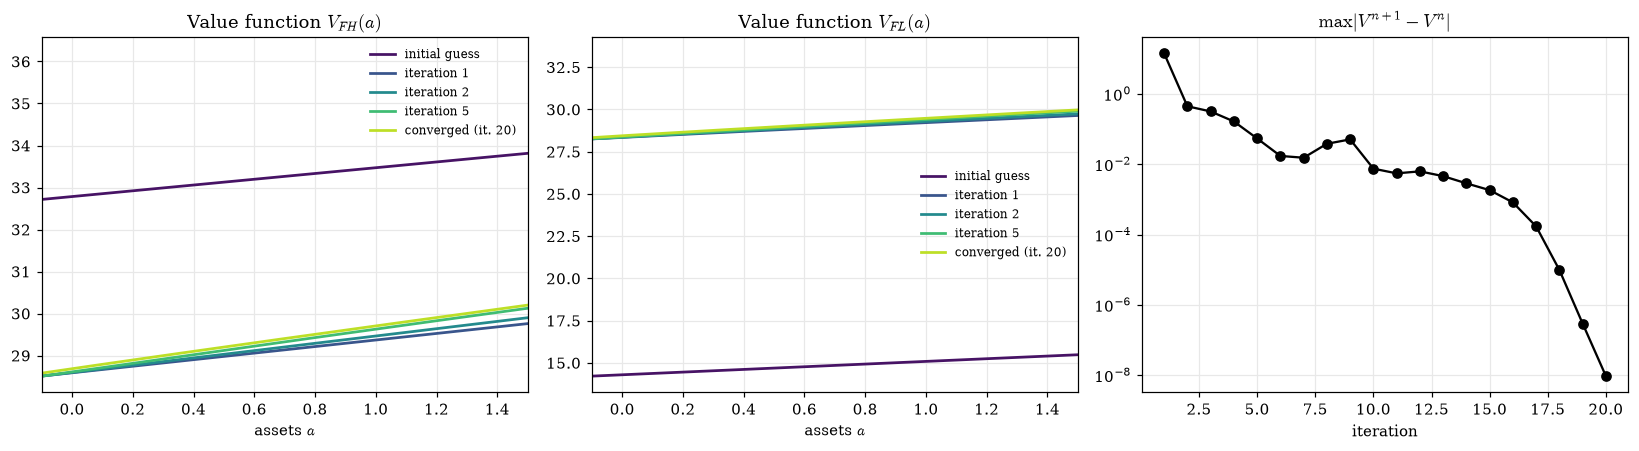

In [12]:
sol_trial = solve_given_r(r_trial, tau, params, keep_history=True)
print(f"Converged in {sol_trial['iters']} iterations; final change = {sol_trial['resid'][-1]:.2e}")
display(pd.DataFrame({"iteration": np.arange(1, sol_trial['iters'] + 1), "max|V_new - V_old|": sol_trial["resid"]}).head(8))

hist = sol_trial["hist"]
show = sorted(set([0, 1, 2, 5, len(hist) - 1]))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
cols = plt.cm.viridis(np.linspace(0.05, 0.9, len(show)))
for ax, j in zip(axes[:2], range(2)):
    for k, col in zip(show, cols):
        lab = "initial guess" if k == 0 else (f"iteration {k}" if k < len(hist) - 1 else f"converged (it. {k})")
        ax.plot(a, hist[k][:, j], color=col, lw=1.8, label=lab)
    ax.set_title(f"Value function $V_{{{FORMAL[j]}}}(a)$"); ax.set_xlabel("assets $a$"); ax.set_xlim(-0.1, 1.5); ax.legend(fontsize=8)
axes[2].semilogy(np.arange(1, sol_trial["iters"] + 1), sol_trial["resid"], "o-", color="k")
axes[2].set_title(r"$\max|V^{n+1}-V^n|$"); axes[2].set_xlabel("iteration")
plt.tight_layout(); plt.show()

**Check 2: the converged $V$ solves the HJB.** Plugging $V$ back in, $\rho V - u(c) - \mathcal A V$ should be zero.

In [13]:
def hjb_residual(sol, p):
    N = p["N"]
    Vst = np.concatenate([sol["V"][:, j] for j in range(N)])
    ust = np.concatenate([u(sol["c"][:, j], p["gamma"][j]) for j in range(N)])
    return float(np.max(np.abs(p["rho"] * Vst - ust - sol["A"] @ Vst)))
print(f"max |rho V - u(c) - A V| = {hjb_residual(sol_trial, params):.2e}")

max |rho V - u(c) - A V| = 1.16e-11


### 4e. Policy functions and stationary distribution at $r=0.02$

Mass in FH = 0.7696, FL = 0.2304   (Check 1 targets: 0.7696, 0.2304)
Net assets S(r=0.02) = +0.0657  -> households save more than is borrowed: r too high


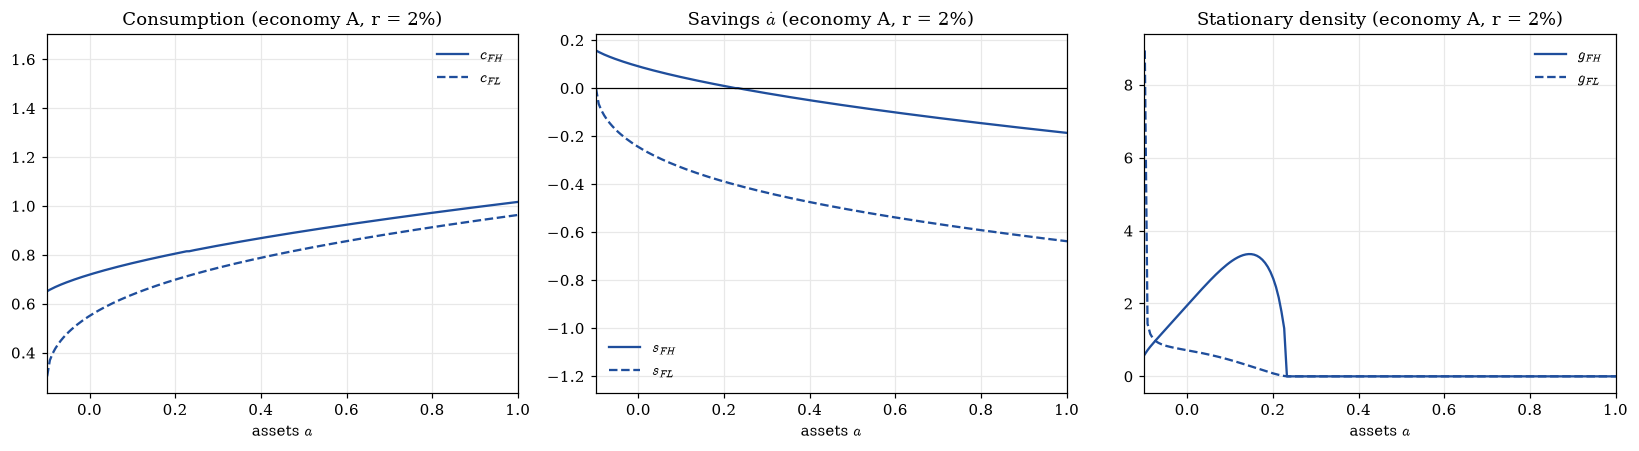

In [14]:
g = sol_trial["g"]; da = params["da"]
print(f"Mass in FH = {g[:,0].sum()*da:.4f}, FL = {g[:,1].sum()*da:.4f}   (Check 1 targets: {p_F[0]:.4f}, {p_F[1]:.4f})")
S_trial = excess_assets(sol_trial, params)
print(f"Net assets S(r=0.02) = {S_trial:+.4f}  -> {'households save more than is borrowed: r too high' if S_trial>0 else 'households borrow more than is saved: r too low'}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for j, (nm, ls) in enumerate(zip(FORMAL, ["-", "--"])):
    axes[0].plot(a, sol_trial["c"][:, j], ls, color=C_A, label=f"$c_{{{nm}}}$")
    axes[1].plot(a, sol_trial["s"][:, j], ls, color=C_A, label=f"$s_{{{nm}}}$")
    axes[2].plot(a, g[:, j], ls, color=C_A, label=f"$g_{{{nm}}}$")
for ax, t in zip(axes, ["Consumption", "Savings $\\dot a$", "Stationary density"]):
    ax.set_title(t + " (economy A, r = 2%)"); ax.set_xlabel("assets $a$"); ax.set_xlim(-0.1, 1.0); ax.legend()
axes[1].axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

---
# Step 5. Equilibrium interest rate (question 1)

### 5a. Excess assets as a function of $r$
$S(r)$ is, broadly, increasing in $r$: a higher rate makes saving more attractive. For very low $r$ everybody sits at the borrowing limit, so $S=a_{\min}$. The equilibrium is where $S$ crosses zero from below. The upper bound for $r$ is $\rho$ (at $r\ge\rho$ households would accumulate without limit). We compute $S(r)$ on a grid for both economies, from the highest $r$ downwards, starting each solve from the $V$ of the previous grid point (warm start, A13).

A: with monotributo: S(r) never decreases on the grid: True (flat at S = a_min for very low r, where everybody is at the borrowing limit)


B: without monotributo: S(r) never decreases on the grid: True (flat at S = a_min for very low r, where everybody is at the borrowing limit)


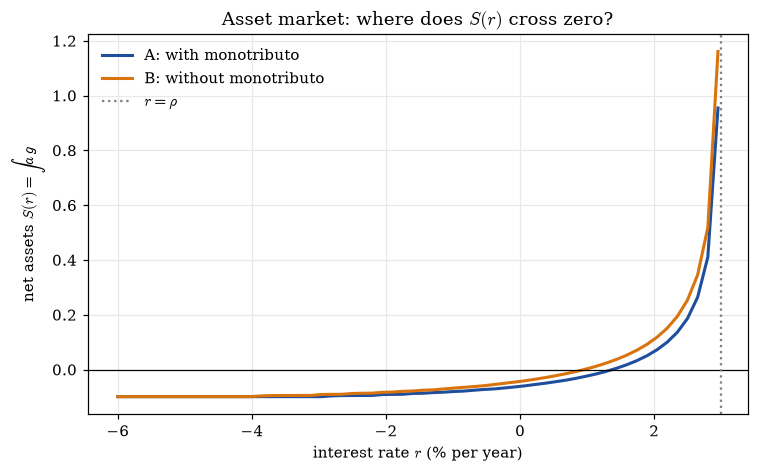

In [15]:
r_grid = np.linspace(-0.06, 0.0295, 60)
S_curves = {}
for E in (ECON_A, ECON_B):
    V, S_list = None, []
    for r in r_grid[::-1]:                       # high r -> low r, warm start
        sol = solve_given_r(r, E["tau"], params, V_init=V); V = sol["V"]; S_list.append(excess_assets(sol, params))
    S_curves[E["name"]] = np.array(S_list[::-1])
    print(f"{E['name']}: S(r) never decreases on the grid: {bool(np.all(np.diff(S_curves[E['name']]) > -1e-9))} "
          f"(flat at S = a_min for very low r, where everybody is at the borrowing limit)")

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(100 * r_grid, S_curves[ECON_A["name"]], color=C_A, lw=2, label=ECON_A["name"])
ax.plot(100 * r_grid, S_curves[ECON_B["name"]], color=C_B, lw=2, label=ECON_B["name"])
ax.axhline(0, color="k", lw=0.8); ax.axvline(100 * params["rho"], color="grey", ls=":", label=r"$r=\rho$")
ax.set_xlabel("interest rate $r$ (% per year)"); ax.set_ylabel(r"net assets $S(r)=\int a\,g$"); ax.set_title("Asset market: where does $S(r)$ cross zero?")
ax.legend(); plt.tight_layout(); plt.show()

### 5b. Bisection (as in notebook 3's `find_equilibrium`)
Start at $r_0=1\%$ with bounds $[r_{\min},r_{\max}]=[-5\%,\ \rho-0.01\%]$. At each step: solve the household problem at $r$, starting from the $V$ of the previous step (warm start), and compute $S$. If $S>0$ (too much saving) set $r_{\max}=r$ and move $r$ halfway down to $r_{\min}$; if $S<0$ set $r_{\min}=r$ and move halfway up to $r_{\max}$. Stop when $|S|<10^{-6}$. The log records every step.

In [16]:
def find_r_star(E, p, r0=0.01, rmin=-0.05, rmax=None, tol_S=1e-6, max_iter=100):
    rmax = p["rho"] - 1e-4 if rmax is None else rmax
    tau, r, V_seed, log = E["tau"], r0, None, []
    for k in range(1, max_iter + 1):
        sol = solve_given_r(r, tau, p, V_init=V_seed)
        S = excess_assets(sol, p)
        log.append(dict(iter=k, r=r, S=S, r_min=rmin, r_max=rmax, HJB_iters=sol["iters"]))
        if S > tol_S:    rmax, r = r, 0.5 * (r + rmin)
        elif S < -tol_S: rmin, r = r, 0.5 * (r + rmax)
        else:            return sol, pd.DataFrame(log)
        V_seed = sol["V"]                                  # warm start for the next r
    raise RuntimeError(f"bisection did not converge in {max_iter} steps (last S = {S:+.2e})")

sol_A, log_A = find_r_star(ECON_A, params)
sol_B, log_B = find_r_star(ECON_B, params)
print("Bisection log, economy A (first 6 and last 3 steps):")
display(pd.concat([log_A.head(6), log_A.tail(3)]).drop_duplicates().round(8))
print("Bisection log, economy B (first 6 and last 3 steps):")
display(pd.concat([log_B.head(6), log_B.tail(3)]).drop_duplicates().round(8))

Bisection log, economy A (first 6 and last 3 steps):


,iter,r,S,r_min,r_max,HJB_iters
0,1,0.010000,-2.357683e-02,-0.050000,0.029900,20
1,2,0.019950,6.495257e-02,0.010000,0.029900,7
2,3,0.014975,9.387930e-03,0.010000,0.019950,6
3,4,0.012488,-8.943040e-03,0.010000,0.014975,6
4,5,0.013731,-4.105700e-04,0.012488,0.014975,5
5,6,0.014353,4.410070e-03,0.013731,0.014975,5
14,15,0.013779,-7.120000e-06,0.013777,0.013780,3
15,16,0.013779,-1.960000e-06,0.013779,0.013780,3
16,17,0.013780,6.100000e-07,0.013779,0.013780,3


Bisection log, economy B (first 6 and last 3 steps):


,iter,r,S,r_min,r_max,HJB_iters
0,1,0.010000,2.890990e-03,-0.050000,0.029900,20
1,2,-0.020000,-8.275474e-02,-0.050000,0.010000,8
2,3,-0.005000,-5.720464e-02,-0.020000,0.010000,7
3,4,0.002500,-3.448915e-02,-0.005000,0.010000,7
4,5,0.006250,-1.811660e-02,0.002500,0.010000,6
5,6,0.008125,-8.310120e-03,0.006250,0.010000,6
13,14,0.009539,1.176000e-05,0.009531,0.009546,3
14,15,0.009535,-1.373000e-05,0.009531,0.009539,3
15,16,0.009537,-9.700000e-07,0.009535,0.009539,3


In [17]:
rA, rB = sol_A["r"], sol_B["r"]
print(f"Equilibrium interest rate, A (with monotributo)   : r*_A = {100*rA:.4f}%   (S = {excess_assets(sol_A, params):+.2e}, {len(log_A)} bisection steps)")
print(f"Equilibrium interest rate, B (without monotributo): r*_B = {100*rB:.4f}%   (S = {excess_assets(sol_B, params):+.2e}, {len(log_B)} bisection steps)")
print(f"Difference r*_B - r*_A = {1e4*(rB-rA):.1f} basis points")
print("Step 8 shows r* moves by about 1 bp when the grid is doubled.")

Equilibrium interest rate, A (with monotributo)   : r*_A = 1.3780%   (S = +6.14e-07, 17 bisection steps)
Equilibrium interest rate, B (without monotributo): r*_B = 0.9537%   (S = -9.68e-07, 16 bisection steps)
Difference r*_B - r*_A = -42.4 basis points
Step 8 shows r* moves by about 1 bp when the grid is doubled.


### 5c. Equilibrium objects and consistency checks
Tax revenue per capita is $\sum_j m_j\,\tau_j z_j$ with $m_j$ the mass in state $j$. It is computed for information only: by A9 it is thrown away.

**Check 3 (resource constraint).** With zero net assets, aggregate consumption must equal aggregate after-tax labour income (interest paid and received nets to zero). A gap would signal a bug in the stationary distribution.

In [18]:
def summarize(sol, p):
    g, a, da, tau, z = sol["g"], p["a"], p["da"], sol["tau"], p["z"]
    m = g.sum(axis=0) * da
    C = float((sol["c"] * g).sum() * da)
    Y_at = float(((1 - tau) * z * m).sum()); Y_pre = float((z * m).sum())
    return {"r* (%)": 100 * sol["r"], "mass FH": m[0], "mass FL": m[1],
            "mean pre-tax income": Y_pre, "tax revenue per capita (discarded)": float((tau * z * m).sum()),
            "effective tax rate": float((tau * z * m).sum() / Y_pre),
            "mean after-tax income": Y_at, "mean consumption": C, "|C - Y_after_tax|": abs(C - Y_at),
            "mean assets": excess_assets(sol, p), "share with a<0": float(((g.sum(axis=1)) * (a < 0)).sum() * da),
            "mass at borrowing limit": float(g[0].sum() * da),
            "mean a | FH": float(g[:, 0] @ a * da / m[0]), "mean a | FL": float(g[:, 1] @ a * da / m[1])}

summ = pd.DataFrame({ECON_A["name"]: summarize(sol_A, params), ECON_B["name"]: summarize(sol_B, params)})
display(summ.round(5))
print("HJB residual A:", f"{hjb_residual(sol_A, params):.1e}", "| B:", f"{hjb_residual(sol_B, params):.1e}")
print(f"Max consumption on the grid: A = {sol_A['c'].max():.3f}, B = {sol_B['c'].max():.3f}")
print(f"Grid points where V is convex: A = {int((np.diff(sol_A['V'], 2, axis=0) > 1e-12).sum())}, B = {int((np.diff(sol_B['V'], 2, axis=0) > 1e-12).sum())}  (0 = concave, as it should be)")
print(f"Smallest V' on the grid: A = {np.diff(sol_A['V'], axis=0).min()/params['da']:.3f}, B = {np.diff(sol_B['V'], axis=0).min()/params['da']:.3f}  (positive: V increasing in a everywhere, no glitches)")

,A: with monotributo,B: without monotributo
r* (%),1.37795,0.95367
mass FH,0.76956,0.76956
mass FL,0.23044,0.23044
mean pre-tax income,0.84356,0.84356
tax revenue per capita (discarded),0.14992,0.13306
effective tax rate,0.17772,0.15774
mean after-tax income,0.69364,0.71050
mean consumption,0.69364,0.71050
|C - Y_after_tax|,0.00000,0.00000
mean assets,0.00000,-0.00000


HJB residual A: 3.4e-12 | B: 3.3e-12
Max consumption on the grid: A = 1.966, B = 2.190
Grid points where V is convex: A = 0, B = 0  (0 = concave, as it should be)
Smallest V' on the grid: A = 0.904, B = 0.889  (positive: V increasing in a everywhere, no glitches)


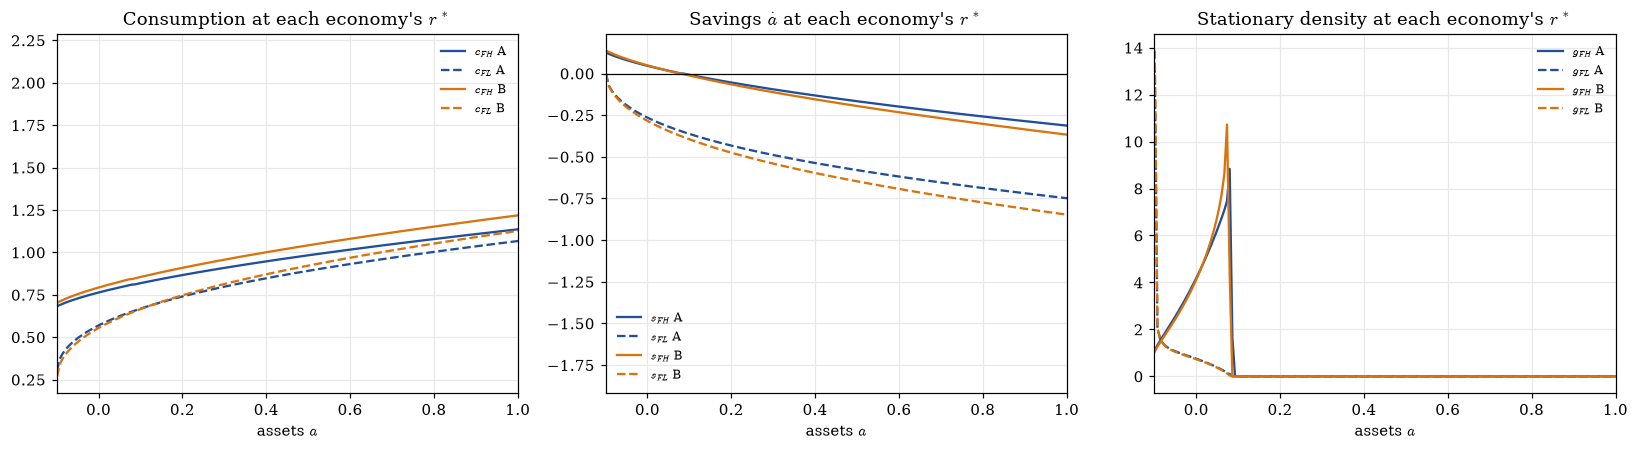

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for sol, E, col in ((sol_A, ECON_A, C_A), (sol_B, ECON_B, C_B)):
    for j, (nm, ls) in enumerate(zip(FORMAL, ["-", "--"])):
        axes[0].plot(a, sol["c"][:, j], ls, color=col, label=f"$c_{{{nm}}}$ {E['name'][0]}")
        axes[1].plot(a, sol["s"][:, j], ls, color=col, label=f"$s_{{{nm}}}$ {E['name'][0]}")
        axes[2].plot(a, sol["g"][:, j], ls, color=col, label=f"$g_{{{nm}}}$ {E['name'][0]}")
for ax, t in zip(axes, ["Consumption", "Savings $\\dot a$", "Stationary density"]):
    ax.set_title(t + " at each economy's $r^*$"); ax.set_xlabel("assets $a$"); ax.set_xlim(-0.1, 1.0); ax.legend(fontsize=8)
axes[1].axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

**Reading the plot above.** Policies are smooth and the value function is concave (checked in 5c: smallest second difference). The tall narrow peak in the density at the left is the **mass point at the borrowing limit**: low-income households who hit $a_{\min}$ stay there (zero drift) until their income improves. On a grid, a point mass shows up as a spike of height mass$/\Delta a$, so it doubles when the grid is refined; the mass itself is reported in 5c ("mass at borrowing limit").

---
# Step 6. Welfare of an agent with initial assets $a_0$ and income $y_0$ (question 2)

By construction $V_j(a)$ **is** the expected discounted lifetime utility of an agent who starts with assets $a$ in income state $j$, follows the optimal policy, and faces the Markov income process and the economy's equilibrium $r^*$ and taxes:

$$W_E(a_0,j_0)=V^E_{j_0}(a_0)=\mathbb E\Big[\int_0^\infty e^{-\rho t}\,u(c_t)\,dt\ \Big|\ a_0,j_0\Big].$$

Agents do not choose the economy; we compare the same $(a_0,j_0)$ across A and B. The two economies differ in two ways at once: the tax schedule, and the equilibrium interest rate that the taxes induce.

### 6a. Value functions

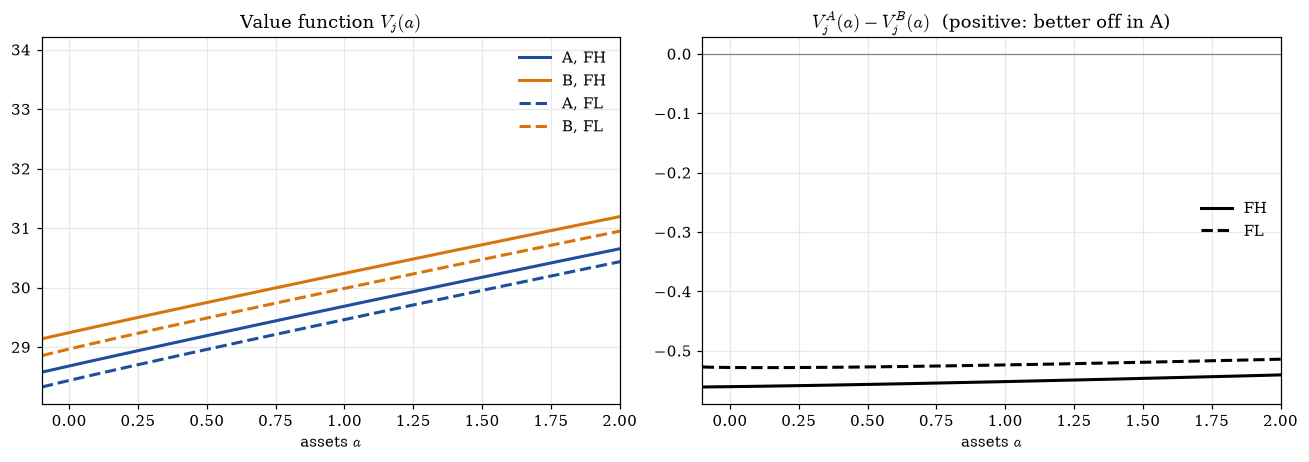

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for j, nm in enumerate(FORMAL):
    axes[0].plot(a, sol_A["V"][:, j], "-" if j == 0 else "--", color=C_A, lw=2, label=f"A, {nm}")
    axes[0].plot(a, sol_B["V"][:, j], "-" if j == 0 else "--", color=C_B, lw=2, label=f"B, {nm}")
axes[0].set_title("Value function $V_j(a)$"); axes[0].set_xlabel("assets $a$"); axes[0].set_xlim(-0.1, 2); axes[0].legend()
for j, nm in enumerate(FORMAL):
    axes[1].plot(a, sol_A["V"][:, j] - sol_B["V"][:, j], "-" if j == 0 else "--", color="k", lw=2, label=f"{nm}")
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_title("$V^A_j(a)-V^B_j(a)$  (positive: better off in A)"); axes[1].set_xlabel("assets $a$"); axes[1].set_xlim(-0.1, 2); axes[1].legend()
plt.tight_layout(); plt.show()

### 6b. Welfare table for selected $(a_0,j_0)$
$V$ is evaluated by linear interpolation on the asset grid. We use assets at the borrowing limit, zero, and three positive levels.

**Consumption-equivalent variation (A12).** Scaling the whole consumption path by $(1+x)$ multiplies CRRA lifetime utility by $(1+x)^{1-\gamma}$. The percent increase in consumption that would make an agent in B as well off as in A is
$$\text{CEV}=\Big(\frac{V^A}{V^B}\Big)^{\frac1{1-\gamma}}-1 .$$
Positive means B-agents would need more consumption to match A. It is a convenient scale, not a different welfare measure.

In [21]:
def welfare(sol, a0, j0, p):
    # V_{j0}(a0) by interpolation; j0 is 0 (FH) or 1 (FL)
    assert p["amin"] <= a0 <= p["amax"], "a0 outside the asset grid"
    return float(np.interp(a0, p["a"], sol["V"][:, j0]))

def cev(VA, VB, gamma): return (VA / VB) ** (1 / (1 - gamma)) - 1

gam = params["gamma"][0]
a0_list = [params["amin"], 0.0, 0.1, 0.5, 1.0]
rows = []
for j0, nm in enumerate(FORMAL):
    for a0 in a0_list:
        VA, VB = welfare(sol_A, a0, j0, params), welfare(sol_B, a0, j0, params)
        rows.append({"y0 (income state)": nm, "a0": a0, "W_A": VA, "W_B": VB, "W_A - W_B": VA - VB,
                     "CEV: B needs +x% consumption": 100 * cev(VA, VB, gam), "better off in": "A" if VA > VB else "B"})
W_table = pd.DataFrame(rows)
display(W_table.round(4))

,y0 (income state),a0,W_A,W_B,W_A - W_B,CEV: B needs +x% consumption,better off in
0,FH,-0.099,28.5773,29.1384,-0.5611,-2.2615,B
1,FH,0.000,28.6812,29.2417,-0.5605,-2.2514,B
2,FH,0.100,28.7848,29.3447,-0.5599,-2.2410,B
3,FH,0.500,29.1907,29.7475,-0.5568,-2.1983,B
4,FH,1.000,29.6862,30.2382,-0.5520,-2.1442,B
5,FL,-0.099,28.3280,28.8554,-0.5274,-2.1469,B
6,FL,0.000,28.4383,28.9665,-0.5282,-2.1420,B
7,FL,0.100,28.5456,29.0740,-0.5285,-2.1349,B
8,FL,0.500,28.9599,29.4872,-0.5273,-2.1006,B
9,FL,1.000,29.4611,29.9850,-0.5239,-2.0525,B


---
# Step 7. Expected aggregate welfare (question 3)

**Definition (A11).** Aggregate welfare in economy $E$ is the value function averaged over that economy's own stationary distribution,
$$\mathcal W_E=\sum_j\int V^E_j(a)\,g^E_j(a)\,da,$$
i.e. the expected lifetime utility of a randomly drawn citizen in the long run. We also split it by income state and report the CEV of the aggregate.

Caveat: A and B have different stationary distributions, so this compares the two *steady states*, not a transition path from one to the other. Average welfare also does not weigh who gains or loses; Step 6 shows the distribution of gains.

In [22]:
def aggregate_welfare(sol, p):
    g, V, da = sol["g"], sol["V"], p["da"]
    m = g.sum(axis=0) * da
    by_state = (V * g).sum(axis=0) * da / m          # E[V | state]
    total = float((V * g).sum() * da)
    return total, by_state, m

WA, WA_s, mA = aggregate_welfare(sol_A, params)
WB, WB_s, mB = aggregate_welfare(sol_B, params)
agg = pd.DataFrame({
    ECON_A["name"]: {"aggregate welfare  W": WA, "E[V | FH]": WA_s[0], "E[V | FL]": WA_s[1], "r* (%)": 100*rA},
    ECON_B["name"]: {"aggregate welfare  W": WB, "E[V | FH]": WB_s[0], "E[V | FL]": WB_s[1], "r* (%)": 100*rB}})
agg["A - B"] = agg.iloc[:, 0] - agg.iloc[:, 1]
display(agg.round(4))
print(f"Aggregate CEV: citizens of B would need {100*cev(WA, WB, gam):+.3f}% more consumption (every period, every state) to match A.")
print("Better off on average in:", "A (with monotributo)" if WA > WB else "B (without monotributo)")

,A: with monotributo,B: without monotributo,A - B
aggregate welfare W,28.6241,29.1770,-0.5529
E[V | FH],28.6990,29.2600,-0.5610
E[V | FL],28.3741,28.8999,-0.5258
r* (%),1.3780,0.9537,0.4243


Aggregate CEV: citizens of B would need -2.226% more consumption (every period, every state) to match A.
Better off on average in: B (without monotributo)


**Tax effect vs interest-rate effect.** Tax revenue is wasted, so any tax is a pure resource loss. Economy A taxes low earners at 5% instead of $\bar\tau\approx15.8\%$ (and high earners at 19%), which raises low earners\' consumption directly; it also changes saving behaviour and hence $r^*$ (Step 5). The decomposition below evaluates A's taxes at B's interest rate (a counterfactual, not an equilibrium) to separate the two.

In [23]:
sol_A_at_rB = solve_given_r(rB, ECON_A["tau"], params)
W_A_at_rB, _, _ = aggregate_welfare(sol_A_at_rB, params)
dec = pd.DataFrame({"welfare W": {"B (tax B, r*_B)": WB, "A tax at r*_B (not an equilibrium)": W_A_at_rB, "A (tax A, r*_A)": WA}})
dec["step"] = ["", "tax effect = %+.4f" % (W_A_at_rB - WB), "interest-rate effect = %+.4f" % (WA - W_A_at_rB)]
display(dec.round(4))

,welfare W,step
"B (tax B, r*_B)",29.1770,
A tax at r*_B (not an equilibrium),28.5992,tax effect = -0.5778
"A (tax A, r*_A)",28.6241,interest-rate effect = +0.0249


---
# Step 9. Who prefers which economy, and how do equilibrium variables differ?

Three questions:
1. Would **all high-income (FH) agents** prefer one economy?
2. Is there a **combination of assets $a$ and income $y$** for which A is better and another for which B is better?
3. How do **equilibrium variables** (interest rate, consumption, savings, borrowing, taxes) differ between A and B?

For 1 and 2 we compare, at every grid point $(a,j)$, the value of being born there in A versus in B, using the CEV of Step 6: $\text{CEV}_j(a)=\big(V^A_j(a)/V^B_j(a)\big)^{1/(1-\gamma)}-1$. Positive means the agent prefers A (B would need that much more consumption to match A); negative means the agent prefers B.

### 9a. Preference at every $(a, y)$
The shaded band marks the assets where households actually live (where either stationary density is positive).

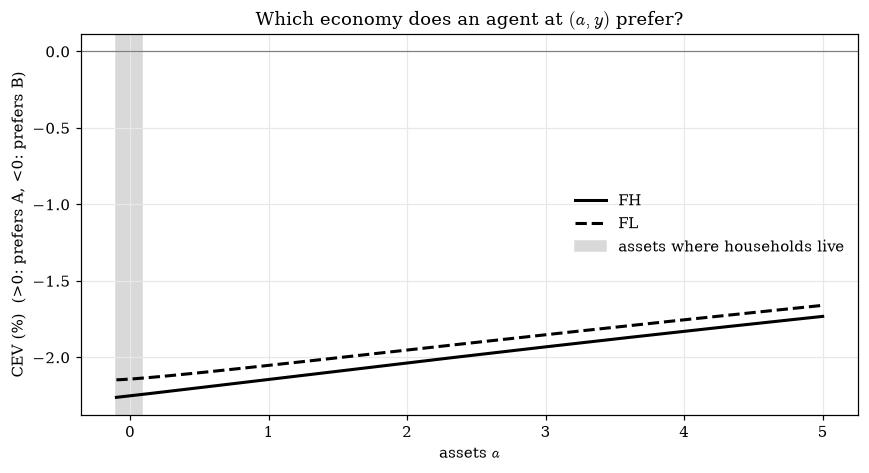

,CEV at a_min (%),CEV at a=0 (%),CEV at a=1 (%),CEV at a=a_max=5 (%),grid points preferring A,of,share of this state's population preferring A (dist. of A),"same, dist. of B"
income state,,,,,,,,
FH,-2.261,-2.251,-2.144,-1.732,0,800,0.0,0.0
FL,-2.147,-2.142,-2.052,-1.660,0,800,0.0,0.0


Households live at a <= 0.086 in both economies.
All FH agents, at every asset level on the grid, prefer: B
All FL agents, at every asset level on the grid, prefer: B


In [24]:
CEV_grid = 100 * cev(sol_A["V"], sol_B["V"], gam)            # (I x 2), in %
lived = (sol_A["g"] > 1e-8) | (sol_B["g"] > 1e-8)
a_live_max = a[lived.any(axis=1)].max()

fig, ax = plt.subplots(figsize=(8, 4.4))
for j, (nm, ls) in enumerate(zip(FORMAL, ["-", "--"])):
    ax.plot(a, CEV_grid[:, j], ls, color="k", lw=2, label=f"{nm}")
ax.axhline(0, color="grey", lw=0.8)
ax.axvspan(params["amin"], a_live_max, color="0.85", label="assets where households live")
ax.set_xlabel("assets $a$"); ax.set_ylabel("CEV (%)  (>0: prefers A, <0: prefers B)")
ax.set_title("Which economy does an agent at $(a, y)$ prefer?"); ax.legend(); plt.tight_layout(); plt.show()

rows = []
for j, nm in enumerate(FORMAL):
    prefA = CEV_grid[:, j] > 0
    mean_a_j = {E: float(sol["g"][:, j] @ a / sol["g"][:, j].sum()) for E, sol in (("A", sol_A), ("B", sol_B))}
    rows.append({"income state": nm,
                 "CEV at a_min (%)": CEV_grid[0, j],
                 "CEV at a=0 (%)": float(np.interp(0.0, a, CEV_grid[:, j])),
                 "CEV at a=1 (%)": float(np.interp(1.0, a, CEV_grid[:, j])),
                 "CEV at a=a_max=5 (%)": CEV_grid[-1, j],
                 "grid points preferring A": int(prefA.sum()), "of": len(a),
                 "share of this state's population preferring A (dist. of A)": float((sol_A["g"][:, j] * prefA).sum() / sol_A["g"][:, j].sum()),
                 "same, dist. of B": float((sol_B["g"][:, j] * prefA).sum() / sol_B["g"][:, j].sum())})
pref = pd.DataFrame(rows).set_index("income state")
display(pref.round(3))
print(f"Households live at a <= {a_live_max:.3f} in both economies.")
for j, nm in enumerate(FORMAL):
    side = "A" if (CEV_grid[:, j] > 0).all() else "B" if (CEV_grid[:, j] < 0).all() else "A or B depending on a"
    print(f"All {nm} agents, at every asset level on the grid, prefer: {side}")

### 9b. Is there any $(a, y)$ where the ranking flips?
In 9a the CEV is negative everywhere on the grid, but it rises with wealth. The reason: wealth earns $r$, and $r^*_A>r^*_B$ (Step 5), so the richer the agent, the more the higher interest rate in A is worth. To see whether it ever overturns the tax advantage of B, we re-solve both economies on a grid that extends to $a=40$, with the same spacing $\Delta a$ (6,400 points). The printout compares $r^*$ with the baseline grid.

**Caveat.** Close to the upper end of the grid the boundary condition at $a_{\max}$ affects $V$, so a crossing near $a_{\max}$ is approximate.

Wide grid: r*_A = 1.3774%, r*_B = 0.9540%  (baseline grid: 1.3780%, 0.9537%)
FH: A becomes better only for a > 34.8  (= 41 times mean pre-tax income; nobody holds more than 0.09)
FL: A becomes better only for a > 33.7  (= 40 times mean pre-tax income; nobody holds more than 0.09)


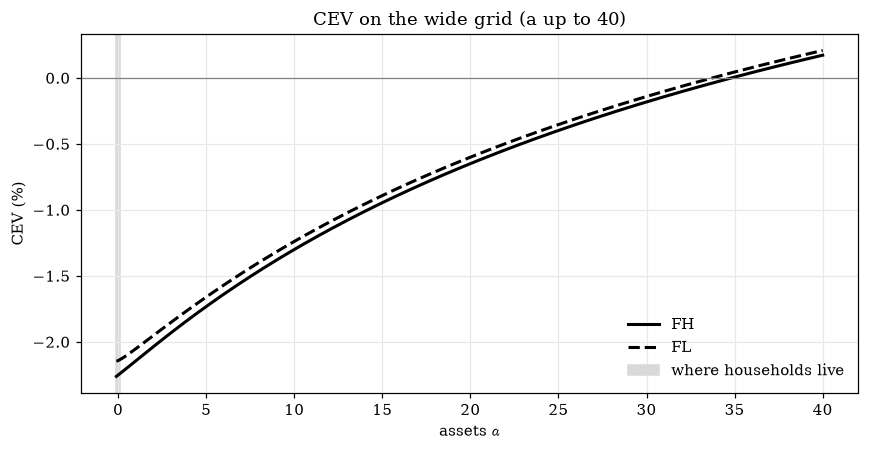

In [25]:
p_wide = make_params(Lam_F, amax=40.0, I=6400)
sA_w, _ = find_r_star(ECON_A, p_wide); sB_w, _ = find_r_star(ECON_B, p_wide)
CEV_w = 100 * cev(sA_w["V"], sB_w["V"], gam)
print(f"Wide grid: r*_A = {100*sA_w['r']:.4f}%, r*_B = {100*sB_w['r']:.4f}%  (baseline grid: {100*rA:.4f}%, {100*rB:.4f}%)")
mean_inc = float((params["z"] * (sol_A["g"].sum(axis=0) * params["da"])).sum())
for j, nm in enumerate(FORMAL):
    k = np.where(np.diff(np.sign(CEV_w[:, j])) != 0)[0]
    if len(k):
        a_x = p_wide["a"][k[0]]
        print(f"{nm}: A becomes better only for a > {a_x:.1f}  (= {a_x/mean_inc:.0f} times mean pre-tax income; nobody holds more than {a_live_max:.2f})")
    else:
        print(f"{nm}: no crossing up to a = 40")

fig, ax = plt.subplots(figsize=(8, 4.2))
for j, (nm, ls) in enumerate(zip(FORMAL, ["-", "--"])):
    ax.plot(p_wide["a"], CEV_w[:, j], ls, color="k", lw=2, label=nm)
ax.axhline(0, color="grey", lw=0.8); ax.axvspan(params["amin"], a_live_max, color="0.85", label="where households live")
ax.set_xlabel("assets $a$"); ax.set_ylabel("CEV (%)"); ax.set_title("CEV on the wide grid (a up to 40)"); ax.legend()
plt.tight_layout(); plt.show()

**Why do even low earners (FL) prefer B, although A taxes them at 5% instead of 15%?** Income states are short-lived: an FL spell lasts 0.59 years on average, an FH spell 1.97 years, and 77% of the time is spent in FH (Step 1). An FL agent today is mostly an FH agent in the future, where A taxes 19% and B only 15.8%. Over a lifetime the agent pays less tax in B. In aggregate, B collects 11% less revenue than A (Step 5c), because the weights in $\bar\tau$ are population shares, while high earners earn three times as much.

**Tax effect vs interest-rate effect, by $(a, y)$.** Step 7 split aggregate welfare into a tax effect and an interest-rate effect. The same split at every grid point:
- tax effect $=V^{A\text{ tax},\,r^*_B}_j(a)-V^B_j(a)$, where the first term is a counterfactual, not an equilibrium;
- rate effect $=V^A_j(a)-V^{A\text{ tax},\,r^*_B}_j(a)$.

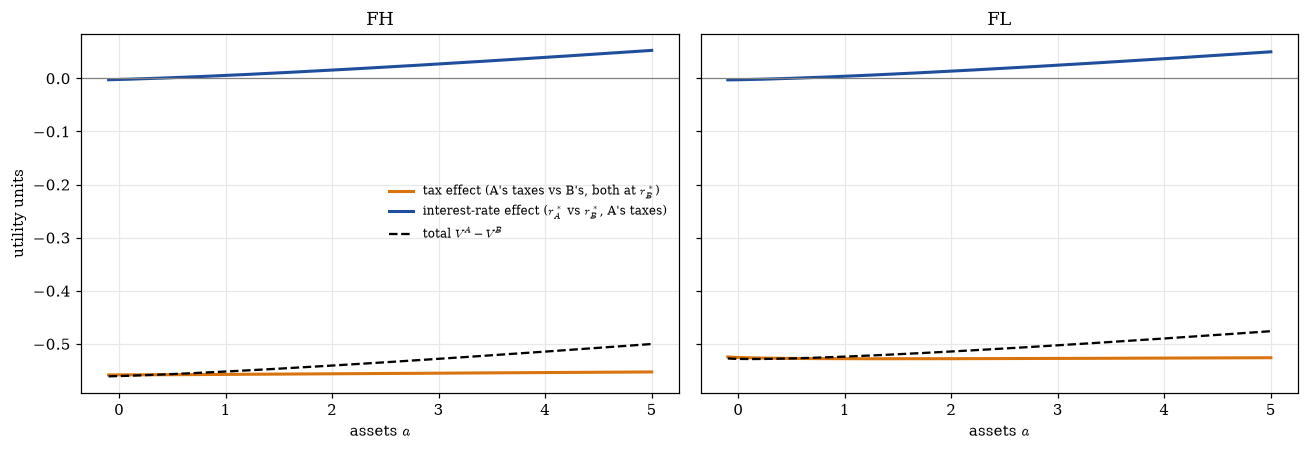

FH at a=0: tax effect -0.5583, rate effect -0.0022, total -0.5605
FL at a=0: tax effect -0.5256, rate effect -0.0027, total -0.5282


In [26]:
tax_eff = sol_A_at_rB["V"] - sol_B["V"]
rate_eff = sol_A["V"] - sol_A_at_rB["V"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for j, nm in enumerate(FORMAL):
    axes[j].plot(a, tax_eff[:, j], color=C_B, lw=2, label="tax effect (A's taxes vs B's, both at $r^*_B$)")
    axes[j].plot(a, rate_eff[:, j], color=C_A, lw=2, label="interest-rate effect ($r^*_A$ vs $r^*_B$, A's taxes)")
    axes[j].plot(a, tax_eff[:, j] + rate_eff[:, j], "k--", lw=1.5, label="total $V^A-V^B$")
    axes[j].axhline(0, color="grey", lw=0.8); axes[j].set_title(f"{nm}"); axes[j].set_xlabel("assets $a$")
axes[0].set_ylabel("utility units"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
for j, nm in enumerate(FORMAL):
    print(f"{nm} at a=0: tax effect {np.interp(0, a, tax_eff[:, j]):+.4f}, rate effect {np.interp(0, a, rate_eff[:, j]):+.4f}, total {np.interp(0, a, tax_eff[:, j]+rate_eff[:, j]):+.4f}")

**Reading the split.** The tax effect is large, negative and almost flat in $a$: B's tax schedule is better for everybody, at every wealth level. The interest-rate effect is about zero near $a=0$, slightly negative for borrowers (A's higher $r$ makes debt more expensive) and positive and growing for savers. Only for extreme wealth (9b, $a\gtrsim34$) is it large enough to overturn the tax effect.

### 9c. Equilibrium variables in A and B
All objects are steady-state averages over each economy's own stationary distribution.
- Gross saving and gross debt are $\int_{a>0} a\,g$ and $\int_{a<0}|a|\,g$; they are equal because net assets are zero.
- The coefficient of variation is the cross-sectional standard deviation divided by the mean.

In [27]:
def eq_vars(sol, p):
    g, c, s_, da, z, tau = sol["g"], sol["c"], sol["s"], p["da"], p["z"], sol["tau"]
    m = g.sum(axis=0) * da
    w = g * da                                              # mass at each (a, j)
    Cbar = float((c * w).sum()); Csd = float(np.sqrt(((c - Cbar) ** 2 * w).sum()))
    out = {"r* (%)": 100 * sol["r"],
           "after-tax income FH": (1 - tau[0]) * z[0], "after-tax income FL": (1 - tau[1]) * z[1],
           "mean after-tax income": float(((1 - tau) * z * m).sum()),
           "tax revenue per capita (discarded)": float((tau * z * m).sum()),
           "mean consumption": Cbar,
           "mean consumption | FH": float((c[:, 0] * w[:, 0]).sum() / m[0]),
           "mean consumption | FL": float((c[:, 1] * w[:, 1]).sum() / m[1]),
           "consumption CV (std/mean)": Csd / Cbar,
           "consumption drop when FH -> FL at a=0": float(np.interp(0, p["a"], c[:, 0]) - np.interp(0, p["a"], c[:, 1])),
           "mean assets | FH": float((p["a"] * w[:, 0]).sum() / m[0]),
           "mean assets | FL": float((p["a"] * w[:, 1]).sum() / m[1]),
           "gross saving (a>0)": float((p["a"][:, None] * w * (p["a"][:, None] > 0)).sum()),
           "gross debt (a<0)": float((-p["a"][:, None] * w * (p["a"][:, None] < 0)).sum()),
           "share borrowing (a<0)": float((w * (p["a"][:, None] < 0)).sum()),
           "mass at borrowing limit": float(w[0].sum()),
           "aggregate welfare W": float((sol["V"] * w).sum())}
    return out

EV = pd.DataFrame({"A (with monotributo)": eq_vars(sol_A, params), "B (without monotributo)": eq_vars(sol_B, params)})
EV["B - A"] = EV.iloc[:, 1] - EV.iloc[:, 0]
EV["B vs A (%)"] = 100 * EV["B - A"] / EV.iloc[:, 0].abs()
display(EV.round(4))

,A (with monotributo),B (without monotributo),B - A,B vs A (%)
r* (%),1.3780,0.9537,-0.4243,-30.7905
after-tax income FH,0.8100,0.8423,0.0323,3.9830
after-tax income FL,0.3051,0.2705,-0.0346,-11.3409
mean after-tax income,0.6936,0.7105,0.0169,2.4299
tax revenue per capita (discarded),0.1499,0.1331,-0.0169,-11.2429
mean consumption,0.6936,0.7105,0.0169,2.4299
mean consumption | FH,0.7722,0.8032,0.0310,4.0169
mean consumption | FL,0.4313,0.4009,-0.0304,-7.0577
consumption CV (std/mean),0.2255,0.2562,0.0307,13.6231
consumption drop when FH -> FL at a=0,0.1940,0.2386,0.0445,22.9512


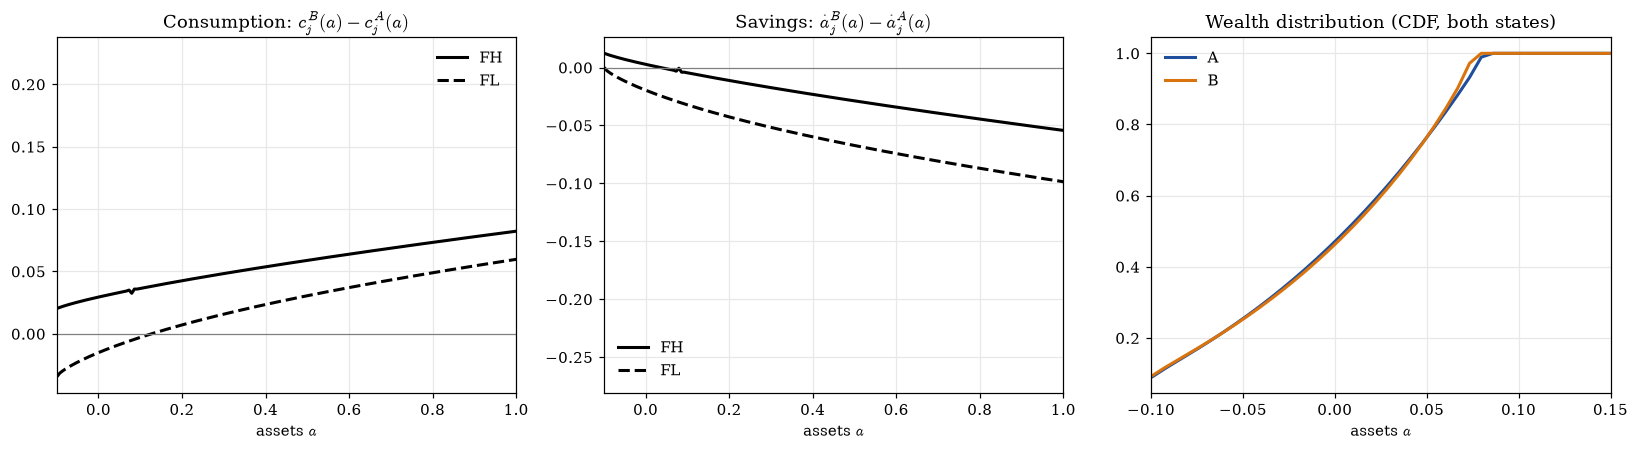

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for j, (nm, ls) in enumerate(zip(FORMAL, ["-", "--"])):
    axes[0].plot(a, sol_B["c"][:, j] - sol_A["c"][:, j], ls, color="k", lw=2, label=nm)
    axes[1].plot(a, sol_B["s"][:, j] - sol_A["s"][:, j], ls, color="k", lw=2, label=nm)
for E, sol, col in (("A", sol_A, C_A), ("B", sol_B, C_B)):
    G = np.cumsum(sol["g"].sum(axis=1)) * params["da"]
    axes[2].plot(a, G, color=col, lw=2, label=E)
axes[0].set_title("Consumption: $c^B_j(a)-c^A_j(a)$"); axes[1].set_title(r"Savings: $\dot a^B_j(a)-\dot a^A_j(a)$")
axes[2].set_title("Wealth distribution (CDF, both states)")
for ax in axes[:2]: ax.axhline(0, color="grey", lw=0.8); ax.set_xlim(-0.1, 1.0); ax.legend()
axes[2].set_xlim(-0.1, 0.15); axes[2].legend()
for ax in axes: ax.set_xlabel("assets $a$")
plt.tight_layout(); plt.show()

**Reading 9c.**
- **Consumption.** Net assets are zero, so mean consumption equals mean after-tax income. B's mean consumption is higher by exactly the revenue it does not collect (tax revenue is thrown away).
- **By state.** FH agents consume more in B (15.8% tax instead of 19%) at every wealth level. FL agents consume less in B (15.8% instead of 5%) wherever households actually live. Only above $a\approx0.12$, a wealth level nobody holds, would an FL agent consume more in B, because they expect to be FH soon and to pay less tax then (left panel).
- **Insurance.** The consumption drop when income falls from FH to FL, and the cross-sectional dispersion of consumption (CV), are both larger in B. A's lower tax on low earners works as insurance against the income shock.
- **Interest rate.** In A, low earners keep more of their income, so they need to borrow less in bad times and save less for them in good times (less precautionary saving). That pushes $r^*$ up. In B, the after-tax income gap is larger, so precautionary saving is stronger and $r^*$ is lower.
- **Borrowing and saving.** The amount of credit barely changes: gross debt (= gross saving) is 0.7% lower in B, and the share of households in debt falls slightly. The difference is at the bottom: more households sit at the borrowing limit in B, and FL households hold slightly more debt on average. So B's lower $r$ does not create more credit; it is the price at which the same amount of credit clears when low earners face a bigger income drop.

---
# Step 8. Sensitivity to the DECIDE items

Each row changes one assumption and recomputes everything (equilibrium, aggregate welfare). Economy A is always (0.19, 0.05); the "no-monotributo" economy changes where noted. The last two rows change only numerics (pseudo-time step, grid).

**Numerical precision.** The pseudo-time step does not move anything, and doubling the grid moves $r^*$ by under 1 bp and the CEV in the third decimal. The economic rows (B's rate, $\Lambda$, $a_{\min}$, $\rho$) are the ones that matter; the 19% and 17% rows show how the ranking depends on B's rate.

In [29]:
def run_pair(p, tauA=(0.19, 0.05), tauB=None):
    if tauB is None:                                   # A8: weighted average with this Lambda's ergodic shares
        pr = stationary(p["Lam"]); tb = pr[0] * tauA[0] + pr[1] * tauA[1]; tauB = (tb, tb)
    try:
        sA, _ = find_r_star(dict(name="A", tau=np.array(tauA)), p)
        sB, _ = find_r_star(dict(name="B", tau=np.array(tauB)), p)
    except (AssertionError, RuntimeError) as e:
        print("  failed:", e); return dict(tauB=tauB[0], rA=np.nan, rB=np.nan, WA=np.nan, WB=np.nan, CEV=np.nan)
    wA, _, _ = aggregate_welfare(sA, p); wB, _, _ = aggregate_welfare(sB, p)
    return dict(tauB=tauB[0], rA=100*sA["r"], rB=100*sB["r"], WA=wA, WB=wB, CEV=100*cev(wA, wB, p["gamma"][0]))

cases = {
    "Baseline (A3 Option 2, a_min=-0.099, B = weighted avg)": run_pair(params),
    "A8: B = unified 19%":                       run_pair(params, tauB=(0.19, 0.19)),
    "A8: B = unified 17%":                       run_pair(params, tauB=(0.17, 0.17)),
    "A3 Option 1: calibrated 4-state Lambda":    run_pair(make_params(Lam_F_opt1)),
    "A3 Option 3: conditioned P":                run_pair(make_params(Lam_F_opt3)),
    "A7: a_min = -0.20":                         run_pair(make_params(Lam_F, amin=-0.20)),
    "A7: a_min = -0.05":                         run_pair(make_params(Lam_F, amin=-0.05)),
    "A5: rho = 0.05 (notebooks 4/5/8)":          run_pair(make_params(Lam_F, rho=0.05)),
    "Numerics: pseudo-step Delta = 100":         run_pair(make_params(Lam_F, Delta=100.0)),
    "Numerics: 1600 grid points":                run_pair(make_params(Lam_F, I=1600)),
}
sens = pd.DataFrame(cases).T
sens.columns = ["tax rate in B", "r*_A (%)", "r*_B (%)", "W_A", "W_B", "CEV: B needs +x% to match A"]
sens.insert(3, "r*_B - r*_A (bp)", 100 * (sens["r*_B (%)"] - sens["r*_A (%)"]))
display(sens.round(4))

,tax rate in B,r*_A (%),r*_B (%),r*_B - r*_A (bp),W_A,W_B,CEV: B needs +x% to match A
"Baseline (A3 Option 2, a_min=-0.099, B = weighted avg)",0.1577,1.3780,0.9537,-42.4279,28.6241,29.1770,-2.2256
A8: B = unified 19%,0.1900,1.3780,1.0148,-36.3135,28.6241,28.2268,1.6582
A8: B = unified 17%,0.1700,1.3780,0.9767,-40.1299,28.6241,28.8165,-0.7849
A3 Option 1: calibrated 4-state Lambda,0.1517,1.1430,0.6223,-52.0750,27.8480,28.4707,-2.5684
A3 Option 3: conditioned P,0.1602,1.4572,1.0563,-40.0909,28.9418,29.4647,-2.0848
A7: a_min = -0.20,0.1577,2.1947,1.9427,-25.2037,28.6628,29.2266,-2.2657
A7: a_min = -0.05,0.1577,0.4049,-0.1814,-58.6304,28.5901,29.1348,-2.1957
A5: rho = 0.05 (notebooks 4/5/8),0.1577,3.3695,2.9442,-42.5295,17.1737,17.5052,-2.2246
Numerics: pseudo-step Delta = 100,0.1577,1.3780,0.9537,-42.4279,28.6241,29.1770,-2.2256
Numerics: 1600 grid points,0.1577,1.3808,0.9569,-42.3913,28.6254,29.1785,-2.2263


---
# Summary

In [30]:
print("RESULTS (baseline assumptions A1-A13)")
print("-" * 70)
print(f"1. Equilibrium interest rate:   r*_A = {100*rA:.3f}%   r*_B = {100*rB:.3f}%   (B - A = {1e4*(rB-rA):+.0f} bp)   [~1 bp grid error, Step 8]")
print(f"2. Individual welfare V(a0,y0): see Step 6 (a0=0, FL: A={welfare(sol_A,0,1,params):.3f}, B={welfare(sol_B,0,1,params):.3f};"
      f" a0=0, FH: A={welfare(sol_A,0,0,params):.3f}, B={welfare(sol_B,0,0,params):.3f})")
print(f"3. Aggregate welfare:           W_A = {WA:.4f}   W_B = {WB:.4f}   (CEV {100*cev(WA, WB, gam):+.2f}% in favour of {'A' if WA>WB else 'B'})")
print(f"4. Who prefers which economy: FH prefers {'A' if (CEV_grid[:,0]>0).all() else 'B' if (CEV_grid[:,0]<0).all() else 'mixed'} at every a on the grid; "
      f"FL prefers {'A' if (CEV_grid[:,1]>0).all() else 'B' if (CEV_grid[:,1]<0).all() else 'mixed'} at every a (Step 9a-9b)")
print(f"5. Mean consumption: A = {EV.loc['mean consumption'].iloc[0]:.4f}, B = {EV.loc['mean consumption'].iloc[1]:.4f}; "
      f"consumption CV: A = {EV.loc['consumption CV (std/mean)'].iloc[0]:.3f}, B = {EV.loc['consumption CV (std/mean)'].iloc[1]:.3f} (Step 9c)")
print(f"   Tax revenue discarded per capita: A = {summ.loc['tax revenue per capita (discarded)'].iloc[0]:.4f}, B = {summ.loc['tax revenue per capita (discarded)'].iloc[1]:.4f}  (mean pre-tax income {summ.loc['mean pre-tax income'].iloc[0]:.3f})")

RESULTS (baseline assumptions A1-A13)
----------------------------------------------------------------------
1. Equilibrium interest rate:   r*_A = 1.378%   r*_B = 0.954%   (B - A = -42 bp)   [~1 bp grid error, Step 8]
2. Individual welfare V(a0,y0): see Step 6 (a0=0, FL: A=28.438, B=28.966; a0=0, FH: A=28.681, B=29.242)
3. Aggregate welfare:           W_A = 28.6241   W_B = 29.1770   (CEV -2.23% in favour of B)
4. Who prefers which economy: FH prefers B at every a on the grid; FL prefers B at every a (Step 9a-9b)
5. Mean consumption: A = 0.6936, B = 0.7105; consumption CV: A = 0.226, B = 0.256 (Step 9c)
   Tax revenue discarded per capita: A = 0.1499, B = 0.1331  (mean pre-tax income 0.844)


## Open decisions for you

1. **A3, the formal-only $\Lambda$.** Option 2 (you chose it): rates from $\log(P)/0.25$ without the 42%-informality rescaling, then informality switched off. Options 1 and 3 are in the sensitivity table. The saved calibrated matrix (Option 1) does not reproduce the $P$ file in the repo (data-file check in Step 1c), so `2. galindo_lambdas_4state.R` should be re-run on the current $P$ if Option 1 is ever used.
2. **A8, what "without monotributo" means.** Set to the weighted-average rate (about 15.8%) for everybody, as you instructed; 19% and 17% for all are in the sensitivity table.
3. **A7, the borrowing limit.** The thesis value $-0.099$ was set with an informal sector and a premium $\theta_I$; in a formal-only economy it is a free choice. The sensitivity table shows how much it moves $r^*$.
4. **Interest rate.** Here $r^*$ is endogenous (market clearing with $\rho=0.03$). Your notes ask whether to fix $r$ (e.g. at 0 or a negative value) as in the new paper. If so, Step 5 is replaced by a fixed $r$ and the comparison becomes partial equilibrium.
5. **Welfare weighting.** Aggregate welfare uses each economy's own stationary distribution. A common initial distribution (e.g. everyone at $a_0=0$ with the ergodic income split) is an alternative and can be added in one cell.